# 계절성 검사 및 STL 알고리즘 매칭 데모

## 구현 흐름

1. 필요한 라이브러리와 저장 폴더를 준비한다.
2. 실제 입도 관광객 일별 데이터의 경로를 지정한다.
3. 실제 데이터셋을 읽고 분석에 필요한 형태로 정리한다.
4. 시계열 구조와 계절성 여부를 검사한다.
5. 검사 결과에 따라 데이터셋 태그를 생성한다.
6. 데이터셋 메타데이터와 STL 알고리즘 메타데이터를 JSON으로 저장한다.
7. 모든 메타데이터 JSON을 읽어 하나의 JSON으로 통합한다.
8. 데이터셋 태그와 STL 필수 태그를 비교한다.
9. STL 적용이 가능하면 시계열 분해를 실행한다.
10. STL 분해 결과를 표준 JSON 형식으로 저장한다.


In [10]:
# 라이브러리 설치
%pip install pandas numpy statsmodels matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. 라이브러리 및 경로 설정

데이터 처리에는 pandas와 NumPy를 사용하고, 시계열 분해에는 statsmodels의 STL을 사용한다.

실행 결과로 생성되는 데이터, 메타데이터, 분석 결과를 각각 다른 폴더에 저장한다.

In [1]:
# 라이브러리 및 폴더 설정
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL


# 현재 주피터 노트북이 실행되는 위치
BASE_DIR = Path.cwd()

# 파일 종류별 저장 폴더
DATA_DIR = BASE_DIR / "data"
METADATA_DIR = BASE_DIR / "metadata"
RESULT_DIR = BASE_DIR / "results"

# 폴더가 없으면 생성
DATA_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("기준 경로:", BASE_DIR)
print("데이터 폴더:", DATA_DIR)
print("메타데이터 폴더:", METADATA_DIR)
print("결과 폴더:", RESULT_DIR)

기준 경로: c:\Dev\tour-anomaly-benchmark\benchmark
데이터 폴더: c:\Dev\tour-anomaly-benchmark\benchmark\data
메타데이터 폴더: c:\Dev\tour-anomaly-benchmark\benchmark\metadata
결과 폴더: c:\Dev\tour-anomaly-benchmark\benchmark\results


## 2. 실제 입도 관광객 데이터 경로 지정

`data` 폴더에 저장된 입도 관광객 일별 CSV 파일의 경로를 지정한다.


In [2]:
# 실제 입도 관광객 일별 데이터 경로
data_path = (
    DATA_DIR
    / "입도 관광객 추이(일별).csv"
)

print("분석 데이터 경로:", data_path)


분석 데이터 경로: c:\Dev\tour-anomaly-benchmark\benchmark\data\입도 관광객 추이(일별).csv


## 3. 실제 데이터셋 읽기

입도 관광객 일별 CSV 파일을 읽고, 날짜와 전체 관광객 수를 분석에 사용할 형태로 정리한다.

전체 관광객 수의 결측값은 앞뒤 날짜의 값을 이용한 선형 보간으로 처리한다.


In [13]:
# 데이터 읽기 및 자료형 변환
# 실제 CSV 파일 읽기
dataset_df = pd.read_csv(
    data_path,
    encoding="utf-8-sig",
)

# 실제 CSV의 컬럼명 지정
time_column = "기준일자(YYYYMMDD)"
value_column = "전체방문객수"

# 기준일자를 날짜 자료형으로 변환
# 예: 20260902 → 2026-09-02
dataset_df[time_column] = pd.to_datetime(
    dataset_df[time_column].astype(str),
    format="%Y%m%d",
    errors="coerce",
)

# 전체 방문객 수를 숫자 자료형으로 변환
dataset_df[value_column] = pd.to_numeric(
    dataset_df[value_column],
    errors="coerce",
)

# 날짜가 과거 → 최근 순서가 되도록 정렬
dataset_df = (
    dataset_df
    .sort_values(time_column)
    .reset_index(drop=True)
)

# 전체 방문객 수의 결측값을 선형 보간
dataset_df[value_column] = (
    dataset_df[value_column]
    .interpolate(
        method="linear",
        limit_direction="both",
    )
)

print("데이터 크기:", dataset_df.shape)

print("\n자료형:")
print(dataset_df.dtypes)

display(dataset_df.head())

데이터 크기: (4993, 4)

자료형:
기준일자(YYYYMMDD)    datetime64[ns]
내국인방문객수                  float64
외국인방문객수                  float64
전체방문객수                   float64
dtype: object


,기준일자(YYYYMMDD),내국인방문객수,외국인방문객수,전체방문객수
0,2013-01-01,NaN,NaN,17010.0
1,2013-01-02,NaN,NaN,22121.0
2,2013-01-03,NaN,NaN,22305.0
3,2013-01-04,NaN,NaN,20604.0
4,2013-01-05,NaN,NaN,20286.0


## 4. 시계열 구조 검사

시계열 데이터 여부를 다음 조건으로 검사한다.

1. 날짜 컬럼이 존재한다.
2. 분석 대상 컬럼이 존재한다.
3. 날짜 컬럼이 datetime 자료형이다.
4. 분석 대상 컬럼이 숫자형이다.
5. 관측 간격이 일정하다.
6. 결측값이 없다.

일별 데이터의 주간 계절성을 검사하므로 계절 주기는 7로 설정한다.  
STL 적용을 위해 최소 두 번 이상의 계절 주기, 즉 14일 이상의 데이터가 필요하다고 설정한다.


In [14]:
# 일별 데이터의 주간 계절 주기
seasonal_period = 7

# 기본 컬럼 조건 확인
has_time_column = (
    time_column in dataset_df.columns
)

has_value_column = (
    value_column in dataset_df.columns
)

# 자료형 확인
is_datetime = pd.api.types.is_datetime64_any_dtype(
    dataset_df[time_column]
)

is_numeric = pd.api.types.is_numeric_dtype(
    dataset_df[value_column]
)

# 결측치 확인
has_no_missing_values = (
    dataset_df[
        [time_column, value_column]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

# 날짜 컬럼을 인덱스로 사용하는 시계열 생성
series = (
    dataset_df
    .set_index(time_column)[value_column]
    .sort_index()
)

# 날짜 간격 추정
inferred_frequency = pd.infer_freq(
    series.index
)

# 일정한 일별 간격인지 확인
is_regular_interval = (
    inferred_frequency == "D"
)

# 최소 두 번 이상의 계절 주기가 있는지 확인
has_enough_data = (
    len(series)
    >= seasonal_period * 2
)

# 기본적인 시계열 데이터 여부
is_time_series = all([
    has_time_column,
    has_value_column,
    is_datetime,
    is_numeric,
])

print("시계열 여부:", is_time_series)
print("추정 시간 간격:", inferred_frequency)
print("일정한 일별 간격:", is_regular_interval)
print("결측값 없음:", has_no_missing_values)
print("충분한 데이터 길이:", has_enough_data)

시계열 여부: True
추정 시간 간격: D
일정한 일별 간격: True
결측값 없음: True
충분한 데이터 길이: True


## 5. 계절성 여부 검사

계절성은 일정한 주기로 비슷한 패턴이 반복되는 성질이다.

일별 데이터이므로 현재 값과 7일 전 값의 상관성을 계산한다.  
장기 추세가 계절성 점수에 영향을 주지 않도록 먼저 선형 추세를 제거한다.

계절성 점수가 0.5 이상이면 계절성이 있다고 판정한다.

이 임계값은 절대적인 기준이 아니라 이번 데모에서 사용하는 운영 기준이다.

In [15]:
# 계절성 검사 함수
def check_seasonality(
    series,
    period,
    threshold=0.5,
):
    """
    선형 추세를 제거한 뒤,
    지정한 주기만큼 떨어진 값들의 상관성을 계산한다.
    """

    # 결측값 제거 후 숫자형으로 변환
    clean_series = (
        pd.Series(series)
        .dropna()
        .astype(float)
        .reset_index(drop=True)
    )

    # 최소 두 번 이상의 주기가 필요
    minimum_length = period * 2

    if len(clean_series) < minimum_length:
        return {
            "method": "detrended_lag_correlation",
            "period": int(period),
            "score": None,
            "threshold": float(threshold),
            "detected": False,
            "reason": "계절성 검사에 필요한 데이터가 부족합니다.",
        }

    # 시간 순서를 0, 1, 2, ... 형태로 생성
    x = np.arange(
        len(clean_series)
    )

    # 데이터의 선형 추세 계산
    trend_coefficients = np.polyfit(
        x,
        clean_series,
        deg=1,
    )

    estimated_trend = np.polyval(
        trend_coefficients,
        x,
    )

    # 원래 값에서 추세를 제거
    detrended_values = (
        clean_series.to_numpy()
        - estimated_trend
    )

    # 앞부분 값
    previous_values = (
        detrended_values[:-period]
    )

    # period만큼 뒤의 값
    current_values = (
        detrended_values[period:]
    )

    # 두 값 집합 중 하나라도 변화가 없으면 상관계수는 0
    if (
        np.std(previous_values) == 0
        or np.std(current_values) == 0
    ):
        score = 0.0

    else:
        # period만큼 떨어진 값들의 상관계수
        score = float(
            np.corrcoef(
                previous_values,
                current_values,
            )[0, 1]
        )

    # 정해둔 기준 이상이면 계절성 존재
    detected = bool(
        score >= threshold
    )

    return {
        "method": "detrended_lag_correlation",
        "period": int(period),
        "score": score,
        "threshold": float(threshold),
        "detected": detected,
        "reason": (
            "반복 상관성이 기준 이상입니다."
            if detected
            else "반복 상관성이 기준보다 낮습니다."
        ),
    }

In [16]:
# 계절성 검사 실행
# 계절성 판정 기준
seasonality_threshold = 0.5

# 계절성 검사 실행
seasonality_result = check_seasonality(
    series=series,
    period=seasonal_period,
    threshold=seasonality_threshold,
)

print(json.dumps(
    seasonality_result,
    ensure_ascii=False,
    indent=2,
))

{
  "method": "detrended_lag_correlation",
  "period": 7,
  "score": 0.6762329380608423,
  "threshold": 0.5,
  "detected": true,
  "reason": "반복 상관성이 기준 이상입니다."
}


## 6. 데이터셋 태그 생성

데이터 구조와 계절성 검사 결과에 따라 태그를 생성한다.

생성 가능한 주요 태그는 다음과 같다.

- `time-series`: 시계열 데이터
- `daily`: 일별 데이터
- `numeric-target`: 숫자형 분석값 보유
- `regular-interval`: 시간 간격이 일정함
- `seasonal`: 계절성이 탐지됨

In [17]:
# STL 적용 가능 조건
is_stl_applicable = all([
    is_time_series,
    is_regular_interval,
    has_no_missing_values,
    has_enough_data,
    seasonality_result["detected"],
])

# 기본 태그
dataset_tags = []

if is_time_series:
    dataset_tags.append("time-series")

if inferred_frequency == "D":
    dataset_tags.append("daily")

if is_numeric:
    dataset_tags.append("numeric-target")

if is_regular_interval:
    dataset_tags.append("regular-interval")
else:
    dataset_tags.append("irregular-interval")

if seasonality_result["detected"]:
    dataset_tags.append("seasonal")
else:
    dataset_tags.append("non-seasonal")

# 중복 제거 후 정렬
dataset_tags = sorted(
    set(dataset_tags)
)

print("STL 적용 가능:", is_stl_applicable)
print("생성 태그:", dataset_tags)

STL 적용 가능: True
생성 태그: ['daily', 'numeric-target', 'regular-interval', 'seasonal', 'time-series']


## 7. 데이터셋 및 알고리즘 메타데이터 저장

데이터셋 메타데이터에는 데이터의 구조, 계절성 검사 결과, 생성된 태그를 저장한다.

알고리즘 메타데이터에는 STL을 적용하기 위해 필요한 태그와 출력 형식을 저장한다.

In [18]:
# 데이터셋 메타데이터 저장
dataset_metadata = {
    "metadata_type": "dataset",

    "dataset_id": "JEJU_ARRIVAL_DAILY_01",

    "dataset_name": "제주 입도 관광객 추이 일별 데이터",

    "source_file": data_path.name,

    "schema": {
        "row_count": int(
            len(dataset_df)
        ),
        "time_column": time_column,
        "value_column": value_column,
    },

    "time_series": {
        "is_time_series": bool(
            is_time_series
        ),
        "frequency": inferred_frequency,
        "is_regular_interval": bool(
            is_regular_interval
        ),
        "start_date": (
            series.index.min()
            .strftime("%Y-%m-%d")
        ),
        "end_date": (
            series.index.max()
            .strftime("%Y-%m-%d")
        ),
    },

    "seasonality": seasonality_result,

    "tags": dataset_tags,
}

dataset_metadata_path = (
    METADATA_DIR
    / "jeju_arrival_daily_dataset_metadata.json"
)

with open(
    dataset_metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        dataset_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "데이터셋 메타데이터 저장:",
    dataset_metadata_path,
)

데이터셋 메타데이터 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata\jeju_arrival_daily_dataset_metadata.json


In [19]:
# STL 알고리즘 메타데이터 저장
stl_metadata = {
    "metadata_type": "algorithm",

    "algorithm_id": "STL_01",

    "algorithm_name": "STL",

    "category": "time-series-decomposition",

    # STL과 매칭되기 위해 데이터셋이 가져야 할 태그
    "required_tags": [
        "time-series",
        "numeric-target",
        "regular-interval",
        "seasonal",
    ],

    "parameters": {
        "period": int(
            seasonal_period
        ),
        "robust": True,
    },

    "outputs": [
        "observed",
        "trend",
        "seasonal",
        "residual",
    ],
}

stl_metadata_path = (
    METADATA_DIR
    / "stl_algorithm_metadata.json"
)

with open(
    stl_metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        stl_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "STL 메타데이터 저장:",
    stl_metadata_path,
)

STL 메타데이터 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata\stl_algorithm_metadata.json


## 8. 메타데이터 통합

metadata 폴더에 저장된 데이터셋별 메타데이터와 알고리즘별 메타데이터를 모두 읽는다.

읽어온 JSON을 데이터셋 목록과 알고리즘 목록으로 구분하여 하나의 통합 JSON으로 저장한다.

In [20]:
dataset_metadata_list = []
algorithm_metadata_list = []

# metadata 폴더의 JSON 파일을 모두 확인
for json_path in sorted(
    METADATA_DIR.glob("*.json")
):
    # 이전 실행에서 만든 통합 파일은 제외
    if json_path.name == "integrated_metadata.json":
        continue

    # JSON 읽기
    with open(
        json_path,
        "r",
        encoding="utf-8",
    ) as file:
        metadata = json.load(file)

    # metadata_type이 없는 기존 메타데이터도 구조를 보고 분류
    if (
        metadata.get("metadata_type") == "dataset"
        or "dataset_info" in metadata
    ):
        dataset_metadata_list.append(
            metadata
        )

    elif (
        metadata.get("metadata_type") == "algorithm"
        or "algorithm_id" in metadata
    ):
        algorithm_metadata_list.append(
            metadata
        )

# 하나의 통합 메타데이터 구조
integrated_metadata = {
    "metadata_version": "1.0",

    "dataset_count": len(
        dataset_metadata_list
    ),

    "algorithm_count": len(
        algorithm_metadata_list
    ),

    "datasets": dataset_metadata_list,

    "algorithms": algorithm_metadata_list,
}

# 통합 메타데이터 저장 경로
integrated_metadata_path = (
    METADATA_DIR
    / "integrated_metadata.json"
)

with open(
    integrated_metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        integrated_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "통합 메타데이터 저장:",
    integrated_metadata_path,
)

print(
    "데이터셋 메타데이터 수:",
    len(dataset_metadata_list),
)

print(
    "알고리즘 메타데이터 수:",
    len(algorithm_metadata_list),
)

통합 메타데이터 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata\integrated_metadata.json
데이터셋 메타데이터 수: 2
알고리즘 메타데이터 수: 1


## 9. 데이터셋과 STL 알고리즘 매칭

데이터셋이 가진 태그와 STL 알고리즘이 요구하는 태그를 비교한다.

STL의 필수 태그가 데이터셋 태그에 모두 포함되어 있으면 적용 가능하다고 판정한다.

In [21]:
# 태그 기반 알고리즘 매칭
# 데이터셋이 가진 태그
dataset_tag_set = set(
    dataset_metadata["tags"]
)

# STL이 요구하는 필수 태그
required_tag_set = set(
    stl_metadata["required_tags"]
)

# 데이터셋에 없는 필수 태그
missing_tags = sorted(
    required_tag_set
    - dataset_tag_set
)

# 누락된 필수 태그가 없으면 적용 가능
is_matched = (
    len(missing_tags) == 0
)

# 매칭 결과 표준 구조
matching_result = {
    "dataset_id": (
        dataset_metadata["dataset_id"]
    ),

    "algorithm_id": (
        stl_metadata["algorithm_id"]
    ),

    "algorithm_name": (
        stl_metadata["algorithm_name"]
    ),

    "applicable": bool(
        is_matched
    ),

    "dataset_tags": sorted(
        dataset_tag_set
    ),

    "required_tags": sorted(
        required_tag_set
    ),

    "missing_tags": missing_tags,

    "reason": (
        "STL 필수 태그를 모두 만족합니다."
        if is_matched
        else "STL 적용에 필요한 태그가 부족합니다."
    ),
}

print(json.dumps(
    matching_result,
    ensure_ascii=False,
    indent=2,
))

{
  "dataset_id": "JEJU_ARRIVAL_DAILY_01",
  "algorithm_id": "STL_01",
  "algorithm_name": "STL",
  "applicable": true,
  "dataset_tags": [
    "daily",
    "numeric-target",
    "regular-interval",
    "seasonal",
    "time-series"
  ],
  "required_tags": [
    "numeric-target",
    "regular-interval",
    "seasonal",
    "time-series"
  ],
  "missing_tags": [],
  "reason": "STL 필수 태그를 모두 만족합니다."
}


In [22]:
# 매칭 결과 저장
matching_result_path = (
    RESULT_DIR
    / "matching_result.json"
)

with open(
    matching_result_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        matching_result,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "매칭 결과 저장:",
    matching_result_path,
)

매칭 결과 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results\matching_result.json


## 10. STL 실행 및 결과 JSON 표준화

데이터셋과 STL의 매칭 결과가 적용 가능일 때만 STL을 실행한다.

STL은 원본 시계열을 다음 네 가지 항목으로 출력한다.

- `observed`: 원래 관측값
- `trend`: 장기적인 추세
- `seasonal`: 반복되는 계절성
- `residual`: 추세와 계절성을 제외한 잔차

분해 결과는 다른 데이터셋에도 동일한 구조로 적용할 수 있도록 JSON으로 표준화한다.

In [23]:
# STL 실행
if not matching_result["applicable"]:
    raise ValueError(
        "현재 데이터셋에는 STL을 적용할 수 없습니다."
    )

# STL 모델 생성
stl_model = STL(
    series,
    period=seasonal_period,
    robust=True,
)

# STL 분해 실행
stl_result = stl_model.fit()

print("STL 분해 완료")

STL 분해 완료


c:\Users\k20sh\anaconda3\envs\cv\Lib\site-packages\statsmodels\tsa\seasonal\_seasonal.py:403: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\k20sh\anaconda3\envs\cv\Lib\site-packages\statsmodels\tsa\seasonal\_seasonal.py:403: UserWarning: Glyph 52404 (\N{HANGUL SYLLABLE CE}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\k20sh\anaconda3\envs\cv\Lib\site-packages\statsmodels\tsa\seasonal\_seasonal.py:403: UserWarning: Glyph 48169 (\N{HANGUL SYLLABLE BANG}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\k20sh\anaconda3\envs\cv\Lib\site-packages\statsmodels\tsa\seasonal\_seasonal.py:403: UserWarning: Glyph 47928 (\N{HANGUL SYLLABLE MUN}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
c:\Users\k20sh\anaconda3\envs\cv\Lib\site-packages\statsmodels\tsa\seasonal\_seasonal.py:403: UserWarning: Glyph 44061 (\N{HANGUL SYLLABLE GAEG}) missing from font(s) DejaVu Sans.
  fig.tight_layout(

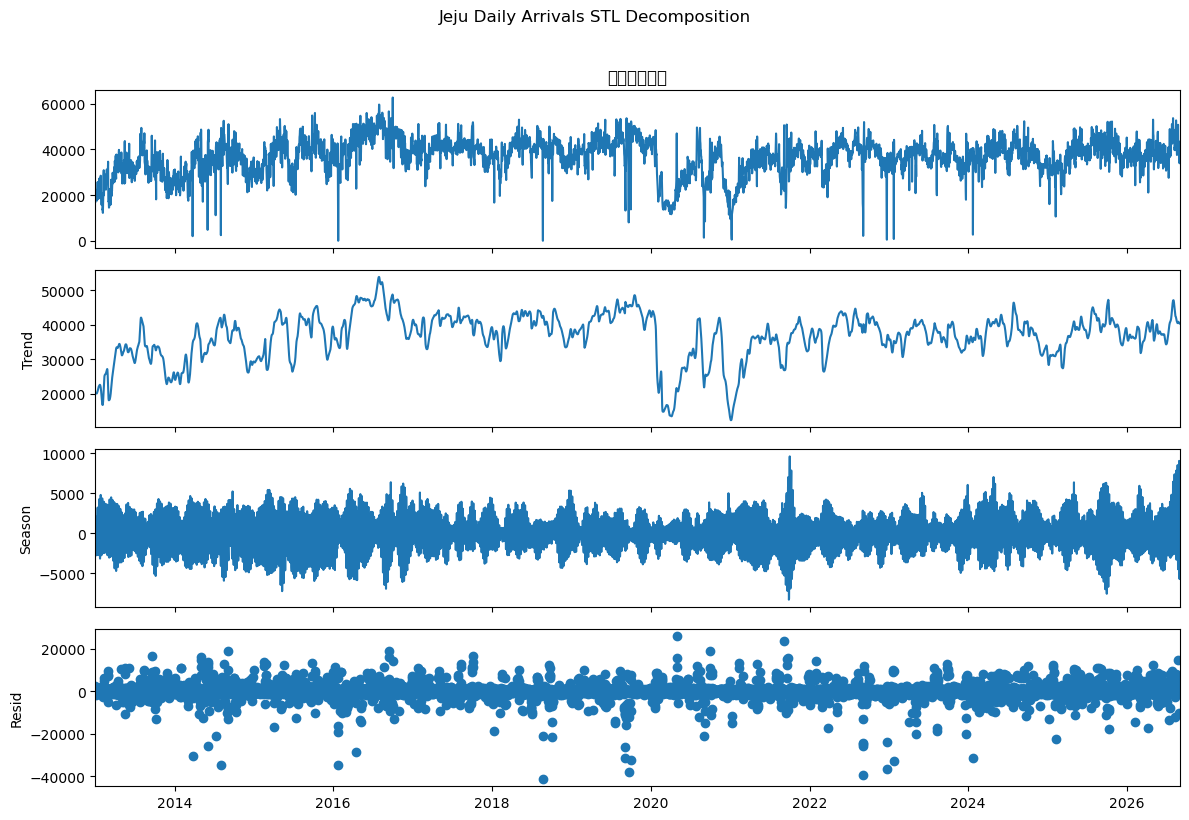

In [24]:
# STL 결과 시각화
figure = stl_result.plot()

figure.set_size_inches(12, 8)

plt.suptitle(
    "Jeju Daily Arrivals STL Decomposition",
    y=1.02,
)

plt.tight_layout()
plt.show()

In [25]:
# STL 결과를 JSON으로 표준화
# STL 결과를 표 형태로 구성
stl_result_df = pd.DataFrame({
    "date": (
        series.index
        .strftime("%Y-%m-%d")
    ),

    "observed": (
        stl_result.observed
        .astype(float)
    ),

    "trend": (
        stl_result.trend
        .astype(float)
    ),

    "seasonal": (
        stl_result.seasonal
        .astype(float)
    ),

    "residual": (
        stl_result.resid
        .astype(float)
    ),
})

# 공통 JSON 결과 구조
standardized_stl_result = {
    "result_type": (
        "time-series-decomposition"
    ),

    "dataset_id": (
        dataset_metadata["dataset_id"]
    ),

    "algorithm_id": (
        stl_metadata["algorithm_id"]
    ),

    "algorithm_name": "STL",

    "execution_status": "success",

    "parameters": {
        "time_column": time_column,
        "value_column": value_column,
        "frequency": inferred_frequency,
        "period": int(
            seasonal_period
        ),
        "robust": True,
    },

    "components": [
        "observed",
        "trend",
        "seasonal",
        "residual",
    ],

    "result_count": int(
        len(stl_result_df)
    ),

    "results": (
        stl_result_df
        .to_dict(orient="records")
    ),
}

In [26]:
# STL 결과 JSON 저장
stl_result_path = (
    RESULT_DIR
    / "stl_decomposition_result.json"
)

with open(
    stl_result_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        standardized_stl_result,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "STL 결과 저장:",
    stl_result_path,
)

STL 결과 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results\stl_decomposition_result.json


## 11. 최종 결과 확인

모든 단계가 정상적으로 실행되었는지 생성된 파일을 확인한다.

In [27]:
output_files = [
    data_path,
    dataset_metadata_path,
    stl_metadata_path,
    integrated_metadata_path,
    matching_result_path,
    stl_result_path,
]

for output_file in output_files:
    print(
        output_file.name,
        "->",
        output_file.exists(),
    )

입도 관광객 추이(일별).csv -> True
jeju_arrival_daily_dataset_metadata.json -> True
stl_algorithm_metadata.json -> True
integrated_metadata.json -> True
matching_result.json -> True
stl_decomposition_result.json -> True


데이터: 4,993행

분석 기간: 2013년부터 2026년까지

날짜 변환: 정상

분석 대상: 전체방문객수

시간 간격: 일별 D

결측값 처리: 완료

계절성 검사 주기: 7일

계절성 점수: 0.6762

판정 기준: 0.5

계절성 판정: True

STL 적용 가능: True

STL 매칭: 성공

STL 분해: 완료

결과 JSON 저장: 완료